### Objective
Analyze property and client data to identify buyer patterns,
segment customers based on their characteristics and preferences,
and generate insights for real-estate investment profiling.

### Project Goals
- Clean and prepare property and client data
- Analyze property and buyer characteristics
- Identify relationships between clients and properties
- Segment buyers based on relevant characteristics
- Profile each buyer segment
- Generate actionable business insights


### 2. Import Libraries

In [514]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### 3. Load Datasets

In [515]:
clients_df=pd.read_csv("clients.csv")
prop_df=pd.read_csv("properties.csv")

In [516]:
prop_df.head()

,listing_id,tower_number,transaction_date,unit_category,unit_number,floor_area_sqft,sale_price,listing_status,client_ref
0,1012,1,01-01-2024,Apartment,12,1160.36,"$300,385.62",Sold,C0027
1,1015,1,01-01-2024,Apartment,15,782.25,"$208,930.81",Sold,C0097
2,1021,1,01-01-2024,Apartment,21,756.21,"$218,585.92",Sold,C0113
3,1030,1,01-01-2024,Apartment,30,743.09,"$246,172.68",Sold,C0141
4,2016,2,01-01-2024,Apartment,16,701.66,"$212,265.67",Sold,C0146


### 4. Initial Data Understanding

#### 4.1 Properties Dataset

In [517]:
prop_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   listing_id        10000 non-null  int64  
 1   tower_number      10000 non-null  int64  
 2   transaction_date  10000 non-null  object 
 3   unit_category     10000 non-null  object 
 4   unit_number       10000 non-null  int64  
 5   floor_area_sqft   10000 non-null  float64
 6   sale_price        10000 non-null  object 
 7   listing_status    10000 non-null  object 
 8   client_ref        7305 non-null   object 
dtypes: float64(1), int64(3), object(5)
memory usage: 703.3+ KB


In [518]:
prop_df.describe(include="all")

,listing_id,tower_number,transaction_date,unit_category,unit_number,floor_area_sqft,sale_price,listing_status,client_ref
count,10000.000000,10000.000000,10000,10000,10000.00000,10000.000000,10000,10000,7305
unique,NaN,NaN,24,2,NaN,NaN,9998,2,2000
top,NaN,NaN,06-01-2024,Apartment,NaN,NaN,"$460,001.26",Sold,C0005
freq,NaN,NaN,537,8547,NaN,NaN,2,7305,13
mean,105898.277400,10.370100,NaN,NaN,28.99920,1139.941412,NaN,NaN,NaN
std,74414.566199,5.769025,NaN,NaN,16.88242,418.373967,NaN,NaN,NaN
min,1002.000000,1.000000,NaN,NaN,1.00000,410.710000,NaN,NaN,NaN
25%,50389.750000,5.000000,NaN,NaN,15.00000,782.200000,NaN,NaN,NaN
50%,100404.500000,10.000000,NaN,NaN,29.00000,1110.880000,NaN,NaN,NaN
75%,150411.250000,15.000000,NaN,NaN,43.00000,1499.000000,NaN,NaN,NaN


In [519]:
prop_df.nunique()

listing_id          10000
tower_number           20
transaction_date       24
unit_category           2
unit_number            70
floor_area_sqft      1208
sale_price           9998
listing_status          2
client_ref           2000
dtype: int64

In [520]:
prop_df.shape

(10000, 9)

####Check data quality

In [521]:
prop_df.isnull().sum()

listing_id             0
tower_number           0
transaction_date       0
unit_category          0
unit_number            0
floor_area_sqft        0
sale_price             0
listing_status         0
client_ref          2695
dtype: int64

In [522]:
round(prop_df['client_ref'].isna().mean()*100,2)

26.95

In [523]:
prop_df.duplicated().sum()

0

Investigate data-quality issues

####Moving to Client Dataset

Since client_ref in the Properties dataset contains missing values, the Client dataset is explored to understand the relationship between both datasets before handling these missing references.

#### 4.2 Clients Dataset

In [524]:
clients_df.head()

,client_id,client_type,first_name,last_name,date_of_birth,gender,country,region,acquisition_purpose,satisfaction_score,loan_applied,referral_channel
0,C0001,Individual,Kareem,Liu,05-11-1968,F,USA,California,Home,4,Yes,Website
1,C0002,Individual,Trystan,Oconnor,11/26/1962,M,USA,California,Home,1,No,Website
2,C0003,Individual,Kale,Gay,04-07-1959,M,USA,California,Home,4,Yes,Agency
3,C0004,Individual,Russell,Gross,11/25/1959,M,USA,California,Home,5,No,Website
4,C0005,Company,Marleez,Co,2/28/1976,M,USA,California,Investment,5,No,Website


In [525]:
clients_df.shape

(2000, 12)

In [526]:
clients_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   client_id            2000 non-null   object
 1   client_type          2000 non-null   object
 2   first_name           2000 non-null   object
 3   last_name            2000 non-null   object
 4   date_of_birth        2000 non-null   object
 5   gender               2000 non-null   object
 6   country              2000 non-null   object
 7   region               2000 non-null   object
 8   acquisition_purpose  2000 non-null   object
 9   satisfaction_score   2000 non-null   int64 
 10  loan_applied         2000 non-null   object
 11  referral_channel     2000 non-null   object
dtypes: int64(1), object(11)
memory usage: 187.6+ KB


In [527]:
clients_df.describe(include="all")

,client_id,client_type,first_name,last_name,date_of_birth,gender,country,region,acquisition_purpose,satisfaction_score,loan_applied,referral_channel
count,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000.000000,2000,2000
unique,2000,2,337,224,1889,2,10,57,2,NaN,2,3
top,C0001,Individual,Carl,Co,6/14/1993,M,USA,California,Home,NaN,No,Website
freq,1,1897,24,103,3,1012,1538,633,1385,NaN,1264,1103
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.029000,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.413562,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.000000,NaN,NaN


In [528]:
clients_df.isnull().sum()

client_id              0
client_type            0
first_name             0
last_name              0
date_of_birth          0
gender                 0
country                0
region                 0
acquisition_purpose    0
satisfaction_score     0
loan_applied           0
referral_channel       0
dtype: int64

In [529]:
clients_df.nunique()

client_id              2000
client_type               2
first_name              337
last_name               224
date_of_birth          1889
gender                    2
country                  10
region                   57
acquisition_purpose       2
satisfaction_score        5
loan_applied              2
referral_channel          3
dtype: int64

In [530]:
clients_df.duplicated().sum()

0

In [531]:
prop_df.columns

Index(['listing_id', 'tower_number', 'transaction_date', 'unit_category',
       'unit_number', 'floor_area_sqft', 'sale_price', 'listing_status',
       'client_ref'],
      dtype='object')

In [532]:
clients_df.columns

Index(['client_id', 'client_type', 'first_name', 'last_name', 'date_of_birth',
       'gender', 'country', 'region', 'acquisition_purpose',
       'satisfaction_score', 'loan_applied', 'referral_channel'],
      dtype='object')

In [533]:
prop_df.nunique()

listing_id          10000
tower_number           20
transaction_date       24
unit_category           2
unit_number            70
floor_area_sqft      1208
sale_price           9998
listing_status          2
client_ref           2000
dtype: int64

In [534]:
clients_df.nunique()

client_id              2000
client_type               2
first_name              337
last_name               224
date_of_birth          1889
gender                    2
country                  10
region                   57
acquisition_purpose       2
satisfaction_score        5
loan_applied              2
referral_channel          3
dtype: int64

In [535]:
(prop_df['client_ref'].isin(clients_df['client_id'])).value_counts()

client_ref
True     7305
False    2695
Name: count, dtype: int64

#### 5. Data Quality Assessment

#### 5.1 Missing Values

The **client_ref** column in the properties dataset is used to link property records with the corresponding client records through **client_id**.

Out of 10,000 property records, 7,305 have valid client references, while 2,695 records have missing client references. Since the missing client references cannot be reliably determined from the available data, they will not be assigned randomly.

In [536]:
prop_df[prop_df['client_ref'].isnull()].head()

,listing_id,tower_number,transaction_date,unit_category,unit_number,floor_area_sqft,sale_price,listing_status,client_ref
11,4039,4,01-01-2024,Apartment,39,785.48,"$216,826.00",Available,NaN
12,5015,5,01-01-2024,Apartment,15,798.50,"$237,680.88",Available,NaN
19,10035,1,01-01-2024,Apartment,4,633.61,"$166,623.12",Available,NaN
20,10052,1,01-01-2024,Apartment,6,740.75,"$233,361.41",Available,NaN
27,10186,1,01-01-2024,Office,23,1201.50,"$399,122.68",Available,NaN


In [537]:
prop_df[prop_df['client_ref'].isnull()]['listing_status'].value_counts()

listing_status
Available    2695
Name: count, dtype: int64

In [538]:
prop_df['listing_status'].unique()

array(['Sold', 'Available'], dtype=object)

### 5.2 Client Reference Validation

The 2,695 properties with missing `client_ref` are **Available for purchase**. Since no client is linked to these properties yet, their `client_ref` is left empty.

#### 6. Actual Data Cleaning

### 6.1 property dataset

In [539]:
prop_df.dtypes

listing_id            int64
tower_number          int64
transaction_date     object
unit_category        object
unit_number           int64
floor_area_sqft     float64
sale_price           object
listing_status       object
client_ref           object
dtype: object

In [540]:
prop_df['transaction_date']=pd.to_datetime(prop_df['transaction_date'])

In [541]:
prop_df['sale_price']=prop_df['sale_price'].str.replace("$","",regex=False)

In [542]:
prop_df['sale_price']=prop_df['sale_price'].str.replace(",","",regex=False)

In [543]:
prop_df['sale_price']=prop_df['sale_price'].astype("float")

In [544]:
prop_df.dtypes

listing_id                   int64
tower_number                 int64
transaction_date    datetime64[ns]
unit_category               object
unit_number                  int64
floor_area_sqft            float64
sale_price                 float64
listing_status              object
client_ref                  object
dtype: object

**Categorical Value Check**

Checking categorical columns for inconsistent or unexpected text values.

In [545]:
prop_df['unit_category'].unique()

array(['Apartment', 'Office'], dtype=object)

In [546]:
prop_df["listing_status"].unique()

array(['Sold', 'Available'], dtype=object)

**Numerical Value Check**

Checking the numerical values to understand their range and statistics.

In [547]:
prop_df[["floor_area_sqft","sale_price"]].describe()

,floor_area_sqft,sale_price
count,10000.000000,10000.000000
mean,1139.941412,344374.678683
std,418.373967,131563.099417
min,410.710000,97402.800000
25%,782.200000,232173.642500
50%,1110.880000,330680.845000
75%,1499.000000,448852.575000
max,1957.160000,736652.270000


**Note:** The numerical values are within a reasonable range, with no obvious invalid values.

In [548]:
prop_df['transaction_date'].min().strftime('%d-%m-%Y'),prop_df['transaction_date'].max().strftime('%d-%m-%Y')

('01-01-2024', '01-12-2025')

In [549]:
prop_df['transaction_date'].unique().strftime('%d-%m-%Y')

array(['01-01-2024', '01-02-2024', '01-03-2024', '01-04-2024',
       '01-05-2024', '01-06-2024', '01-07-2024', '01-08-2024',
       '01-09-2024', '01-10-2024', '01-11-2024', '01-12-2024',
       '01-01-2025', '01-02-2025', '01-03-2025', '01-04-2025',
       '01-05-2025', '01-06-2025', '01-07-2025', '01-08-2025',
       '01-09-2025', '01-10-2025', '01-11-2025', '01-12-2025'],
      dtype=object)

#### 6.2 Detailed cleaning of client data set

In [550]:
clients_df.dtypes

client_id              object
client_type            object
first_name             object
last_name              object
date_of_birth          object
gender                 object
country                object
region                 object
acquisition_purpose    object
satisfaction_score      int64
loan_applied           object
referral_channel       object
dtype: object

In [551]:
clients_df['first_name'].unique()

array(['Kareem', 'Trystan', 'Kale', 'Russell', 'Marleez', 'Yurem',
       'Xavier', 'Kayden', 'Joaquin', 'Nicolas', 'Laci', 'Kylax',
       'Harley', 'Esther', 'Jaylynn', 'Olivia', 'Antonio', 'Luke',
       'Anahi', 'Camille', 'Jesus', 'Araceli', 'Cole', 'Alonso',
       'Rodolfo', 'Joseph', 'Grant', 'Ava', 'Kyla', 'Alanna', 'Skylar',
       'Rodrigo', 'Lydia', 'Lauryn', 'Diego', 'Victor', 'Scarlet',
       'Janelle', 'Aleksandra', 'Conner', 'Zain', 'Maia', 'Jordyn',
       'Diana', 'Kevin', 'Brisa', 'Mason', 'Derick', 'Jace', 'Jair',
       'Matilda', 'Myla', 'Miguel', 'Bridger CAL', 'Mara', 'Erik',
       'Henry', 'Kenyon', 'Oswaldo', 'Kassidy', 'Morgan', 'Tyler',
       'Yesenia', 'Gordon', 'Melanie', 'Enrique', 'Helen', 'Isis',
       'Kayley', 'Donavan', 'Augustus', 'Alejandra', 'Violet', 'Jaelyn',
       'Tristian', 'Christian', 'Nora', 'Dangelo', 'Aiyana', 'Sidney',
       'Kaitlin', 'Issac', 'Zaiden', 'Iris', 'Grace', 'Alessandra',
       'Jamal', 'Irvin', 'Terry', 'Jacqueline'

In [552]:
clients_df['last_name'].unique()

array(['Liu', 'Oconnor', 'Gay', 'Gross', 'Co', 'Wright', 'Faulkner',
       'Olsen', 'Mullins', 'Navarro', 'Guerra', 'Lucero', 'Hickman',
       'Oconnell', 'Porter', 'Lynn', 'Curry', 'Sharp', 'Obrien', 'Nelson',
       'Taylor', 'Terrell', 'Gibson', 'Reeves', 'Weber', 'Phelps',
       'Walker', 'Hess', 'Buchanan', 'Robinson', 'Tate', 'Patrick',
       'Mendez', 'Jensen', 'Hendricks', 'Espinoza', 'Karenina', 'Huff',
       'Horne', 'Chandler', 'Park', 'Hunt', 'Mata', 'Mckee', 'Gilbert',
       'Li', 'Riggs', 'Johns', 'Madden', 'Ewing', 'Walter', 'Franco',
       'Mora', 'Kennedy', 'Palmer', 'Vega', 'Glass', 'Carr', 'Marquez',
       'Brown', 'Ramirez', 'Holland', 'Cardenas', 'Williamson', 'Rios',
       'Nielsen', 'Flowers', 'Hinton', 'Greer', 'Nixon', 'Berger',
       'Fuller', 'Costa', 'Lynch', 'Shea', 'Christensen', 'Cline', 'Owen',
       'Edwards', 'Merritt', 'Larsen', 'Stein', 'Perry', 'Mueller',
       'Ellis', 'Forbes', 'Grant', 'Fischer', 'Howard', 'Huang', 'Meyer',
       'Do

In [553]:
clients_df['date_of_birth'].unique()

array(['05-11-1968', '11/26/1962', '04-07-1959', ..., '9/27/1942',
       '9/13/1963', '6/15/1944'], dtype=object)

###Conversion of date into proper format

In [554]:
clients_df['date_of_birth'].head(20)

0     05-11-1968
1     11/26/1962
2     04-07-1959
3     11/25/1959
4      2/28/1976
5     03-06-1957
6      5/24/1947
7     10/17/1969
8     10-05-1975
9      6/17/1966
10     6/17/1956
11     4/25/1975
12    08-10-1962
13    07-10-1980
14     8/19/1941
15    09-03-1939
16    01-08-1977
17    02-07-1967
18    09-09-1957
19    10/17/1967
Name: date_of_birth, dtype: object

In [555]:
clients_df['date_of_birth']=pd.to_datetime(clients_df['date_of_birth'],format='mixed').dt.strftime('%d-%m-%Y')

In [556]:
clients_df['date_of_birth'] = pd.to_datetime(
    clients_df['date_of_birth'],
    format='%d-%m-%Y'
)

In [557]:
clients_df['date_of_birth'].head()

0   1968-05-11
1   1962-11-26
2   1959-04-07
3   1959-11-25
4   1976-02-28
Name: date_of_birth, dtype: datetime64[ns]

In [558]:
clients_df.dtypes

client_id                      object
client_type                    object
first_name                     object
last_name                      object
date_of_birth          datetime64[ns]
gender                         object
country                        object
region                         object
acquisition_purpose            object
satisfaction_score              int64
loan_applied                   object
referral_channel               object
dtype: object

In [559]:
clients_df['country'].unique()

array(['USA', 'Canada', 'Germany', 'Belgium', 'Mexico', 'Russia', 'UK',
       'Denmark', 'France', 'Australia'], dtype=object)

In [560]:
clients_df['region'].unique()

array(['California', 'Quebec', 'Oregon', 'Arizona', 'Berlin', 'Nevada',
       'Colorado', 'Brussels', 'Mexico City', 'Krasnodar Krai', 'Utah',
       'Northern Ireland', 'Capital Region', 'Virginia', 'Wyoming',
       'Kansas', 'Saint Petersburg', 'Scotland', 'Novosibirsk', 'Ohio',
       'Washington', 'England', 'Texas', 'North Rhine-Westphalia',
       'Florida', 'Ile-de-France', 'British Columbia', 'Puebla',
       'Provence', 'Hamburg', 'Ontario', 'Central Denmark', 'New York',
       'Manitoba', 'Nuevo Leon', 'Normandy', 'Flanders', 'Georgia',
       'Zealand', 'New South Wales', 'Tatarstan', 'Wales', 'Alberta',
       'Baja California', 'Hesse', 'Wallonia', 'Victoria', 'Jalisco',
       'Brittany', 'Bavaria', 'North Denmark', 'South Australia',
       'Occitanie', 'Southern Denmark', 'Queensland', 'Moscow Oblast',
       'Western Australia'], dtype=object)

In [561]:
clients_df['gender'].unique()

array(['F', 'M'], dtype=object)

In [562]:
clients_df['acquisition_purpose'].unique()

array(['Home', 'Investment'], dtype=object)

In [563]:
clients_df['loan_applied'].unique()

array(['Yes', 'No'], dtype=object)

In [564]:
clients_df['referral_channel'].unique()

array(['Website', 'Agency', 'Client'], dtype=object)

In [565]:
clients_df['client_type'].unique()

array(['Individual', 'Company'], dtype=object)

In [566]:
clients_df['satisfaction_score'].describe()

count    2000.000000
mean        3.029000
std         1.413562
min         1.000000
25%         2.000000
50%         3.000000
75%         4.000000
max         5.000000
Name: satisfaction_score, dtype: float64

In [567]:
clients_df['satisfaction_score'].value_counts()

satisfaction_score
4    417
5    405
3    404
1    395
2    379
Name: count, dtype: int64

In [568]:
buyer_property_df=prop_df.merge(clients_df,
                                left_on='client_ref',
                                right_on='client_id',
                                how='left'
                                );

In [569]:
buyer_property_df.shape

(10000, 21)

In [570]:
buyer_property_df.head()

,listing_id,tower_number,transaction_date,unit_category,unit_number,floor_area_sqft,sale_price,listing_status,client_ref,client_id,...,first_name,last_name,date_of_birth,gender,country,region,acquisition_purpose,satisfaction_score,loan_applied,referral_channel
0,1012,1,2024-01-01,Apartment,12,1160.36,300385.62,Sold,C0027,C0027,...,Grant,Weber,1968-09-08,M,USA,California,Home,5.0,Yes,Website
1,1015,1,2024-01-01,Apartment,15,782.25,208930.81,Sold,C0097,C0097,...,Franklin,Mack,1943-06-18,M,USA,Virginia,Home,5.0,Yes,Website
2,1021,1,2024-01-01,Apartment,21,756.21,218585.92,Sold,C0113,C0113,...,Arthur,Bray,1949-07-14,M,USA,Utah,Investment,4.0,No,Agency
3,1030,1,2024-01-01,Apartment,30,743.09,246172.68,Sold,C0141,C0141,...,Madalyn,Mercer,1986-06-21,F,USA,California,Home,5.0,No,Website
4,2016,2,2024-01-01,Apartment,16,701.66,212265.67,Sold,C0146,C0146,...,Hazel,Ayers,1963-02-01,M,USA,Colorado,Home,2.0,No,Website


**7. CLIENT EDA**

### Categorical Feature Distribution

In [571]:
categorical_cols=['client_type','gender','country','region','acquisition_purpose','loan_applied','referral_channel']

In [572]:
for col in categorical_cols:
    print(clients_df[col].value_counts())

client_type
Individual    1897
Company        103
Name: count, dtype: int64
gender
M    1012
F     988
Name: count, dtype: int64
country
USA          1538
UK             95
Canada         85
Germany        56
France         53
Belgium        43
Mexico         40
Australia      39
Russia         36
Denmark        15
Name: count, dtype: int64
region
California                633
Nevada                    143
Colorado                  118
Arizona                   108
Oregon                     96
Utah                       87
Washington                 73
Virginia                   65
Texas                      56
Florida                    50
New York                   49
Georgia                    34
England                    29
Alberta                    27
Scotland                   25
Ohio                       24
Northern Ireland           24
British Columbia           20
Wales                      17
Brittany                   16
Flanders                   16
Hamburg             

In [573]:
clients_df[['satisfaction_score']].value_counts()

satisfaction_score
4                     417
5                     405
3                     404
1                     395
2                     379
Name: count, dtype: int64

### Insights

- Most clients are Individual buyers, while Company clients are fewer.
- USA has the highest number of clients.
- Home purchases are more common than Investment purchases.
- Most clients did not apply for a loan.
- Website is the most common referral channel.
- Gender distribution is nearly balanced.
- Client distribution varies considerably across regions.

In [574]:
from datetime import datetime

clients_df['age'] = (datetime.now() - clients_df['date_of_birth']).dt.days / 365.25
clients_df['age'] = clients_df['age'].round().astype(int)

In [575]:
clients_df['age']

0       58
1       64
2       68
3       67
4       51
        ..
1995    34
1996    84
1997    63
1998    82
1999    31
Name: age, Length: 2000, dtype: int32

C:\Users\user\AppData\Local\Temp\ipykernel_14900\410395269.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=clients_df,x='client_type',palette='coolwarm')


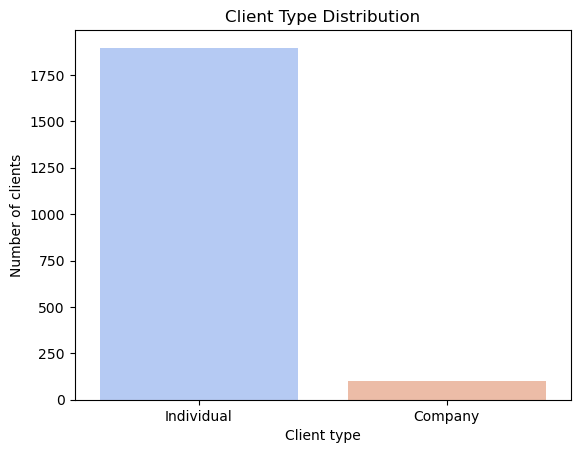

In [576]:
# Visualization 1: Client Type Distribution
sns.countplot(data=clients_df,x='client_type',palette='coolwarm')

plt.title('Client Type Distribution')
plt.xlabel('Client type')
plt.ylabel('Number of clients')
plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_14900\707862119.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=clients_df,x='gender',palette='coolwarm')


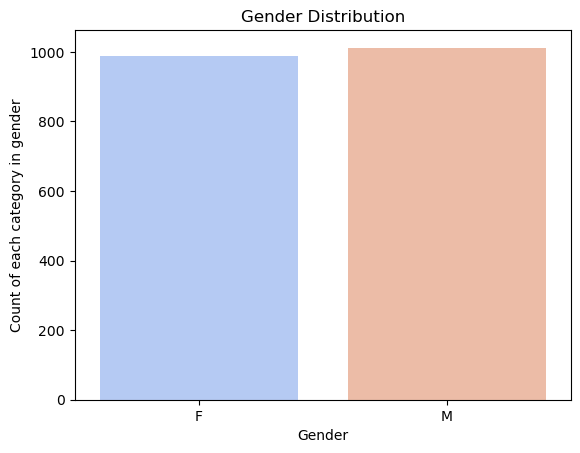

In [577]:
#Visualization 2: Gender Distribution

sns.countplot(data=clients_df,x='gender',palette='coolwarm')
plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Count of each category in gender')
plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_14900\2433858540.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=clients_df,x='acquisition_purpose',palette='coolwarm')


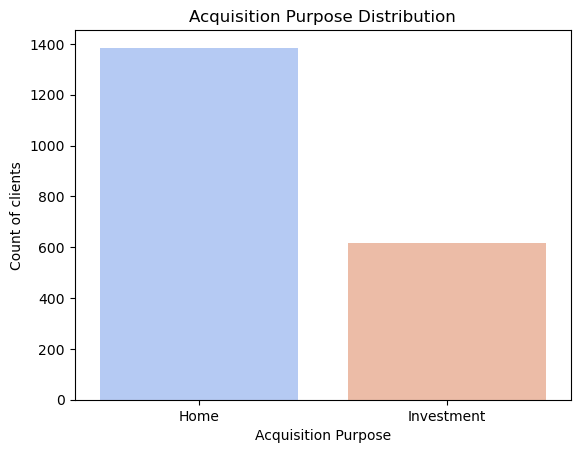

In [578]:
#Visualization 3:Acquisition Purpose Distribution

sns.countplot(data=clients_df,x='acquisition_purpose',palette='coolwarm')
plt.title('Acquisition Purpose Distribution')
plt.xlabel('Acquisition Purpose')
plt.ylabel('Count of clients')
plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_14900\2052372321.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=clients_df,x='loan_applied',palette='coolwarm')


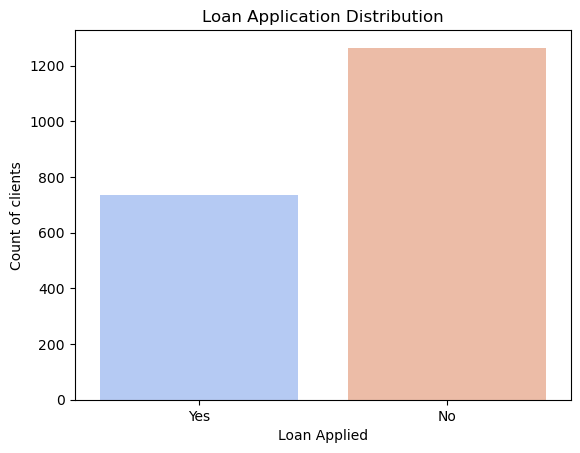

In [579]:
# Visualization 4: Loan application distribution
sns.countplot(data=clients_df,x='loan_applied',palette='coolwarm')
plt.title('Loan Application Distribution')
plt.xlabel('Loan Applied')
plt.ylabel('Count of clients')
plt.show()


C:\Users\user\AppData\Local\Temp\ipykernel_14900\1253143179.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=clients_df,x='referral_channel',palette='coolwarm')


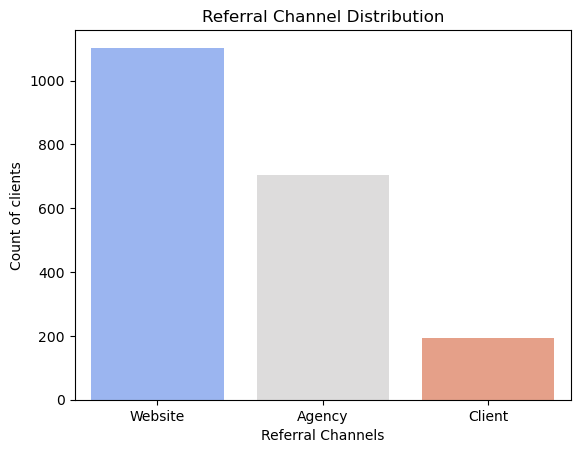

In [580]:
# Visualization 5: Referral Channel Distribution

sns.countplot(data=clients_df,x='referral_channel',palette='coolwarm')
plt.title('Referral Channel Distribution')
plt.xlabel('Referral Channels')
plt.ylabel('Count of clients')
plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_14900\1700049562.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=clients_df,x='satisfaction_score',palette='coolwarm')


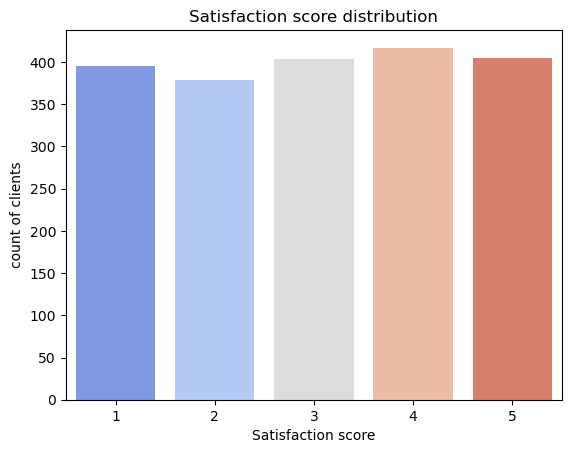

In [581]:
# Visualization 6: Satisfaction Score Distribution

sns.countplot(data=clients_df,x='satisfaction_score',palette='coolwarm')
plt.title('Satisfaction score distribution')
plt.xlabel('Satisfaction score')
plt.ylabel('count of clients')
plt.show()


C:\Users\user\AppData\Local\Temp\ipykernel_14900\1652823050.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=clients_df,x='acquisition_purpose',y='satisfaction_score',palette='coolwarm')


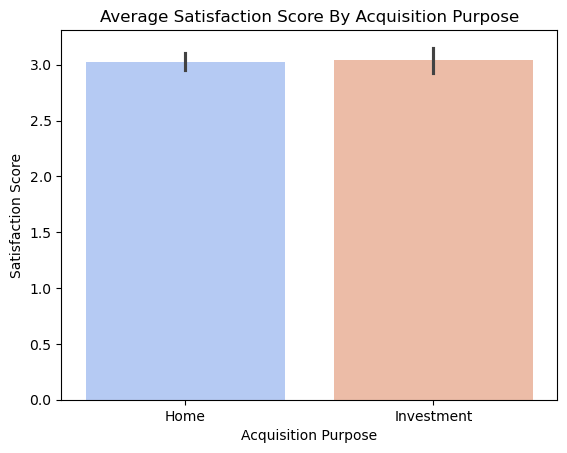

In [582]:
# Visualization 7:Average Satisfaction Score by Acquisition Purpose

sns.barplot(data=clients_df,x='acquisition_purpose',y='satisfaction_score',palette='coolwarm')
plt.title('Average Satisfaction Score By Acquisition Purpose')
plt.xlabel('Acquisition Purpose')
plt.ylabel('Satisfaction Score')
plt.show()

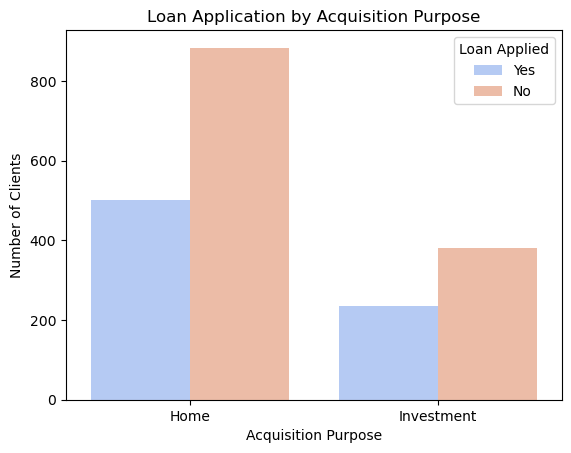

In [583]:
# Visualization 8: Loan Application by Acquisition Purpose

sns.countplot(
    data=clients_df,
    x='acquisition_purpose',
    hue='loan_applied',
    palette='coolwarm'
)

plt.title('Loan Application by Acquisition Purpose')
plt.xlabel('Acquisition Purpose')
plt.ylabel('Number of Clients')
plt.legend(title='Loan Applied')
plt.show()

In [584]:
clients_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   client_id            2000 non-null   object        
 1   client_type          2000 non-null   object        
 2   first_name           2000 non-null   object        
 3   last_name            2000 non-null   object        
 4   date_of_birth        2000 non-null   datetime64[ns]
 5   gender               2000 non-null   object        
 6   country              2000 non-null   object        
 7   region               2000 non-null   object        
 8   acquisition_purpose  2000 non-null   object        
 9   satisfaction_score   2000 non-null   int64         
 10  loan_applied         2000 non-null   object        
 11  referral_channel     2000 non-null   object        
 12  age                  2000 non-null   int32         
dtypes: datetime64[ns](1), int32(1), i

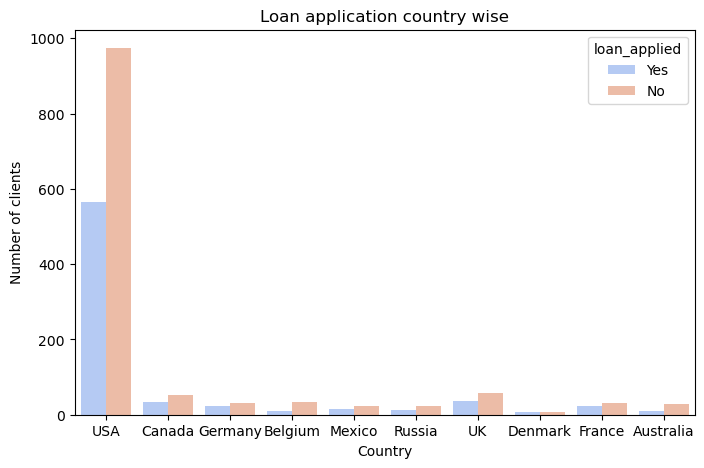

In [585]:
#Visualization 9: Loan application country wise
plt.figure(figsize=(8,5))
sns.countplot(data=clients_df,x='country',hue='loan_applied',palette='coolwarm')
plt.title('Loan application country wise')
plt.xlabel('Country')
plt.ylabel('Number of clients')
plt.show()

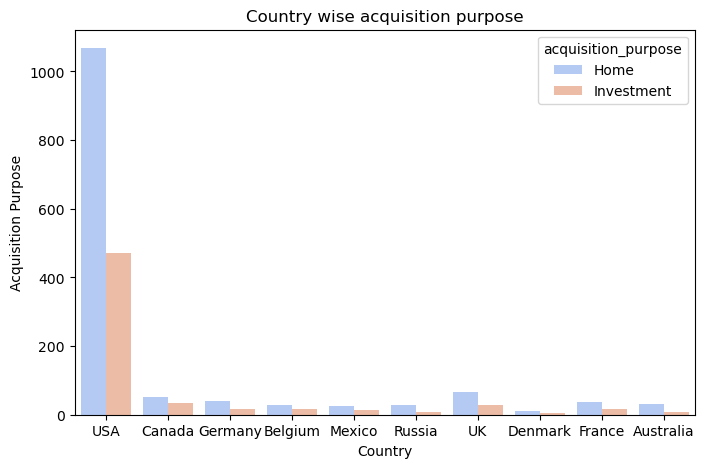

In [586]:
# Visualization 10:Country wise acquisition purpose

plt.figure(figsize=(8,5))
sns.countplot(data=clients_df,x='country',hue='acquisition_purpose',palette='coolwarm')
plt.title('Country wise acquisition purpose')
plt.xlabel('Country')
plt.ylabel('Acquisition Purpose')
plt.show()

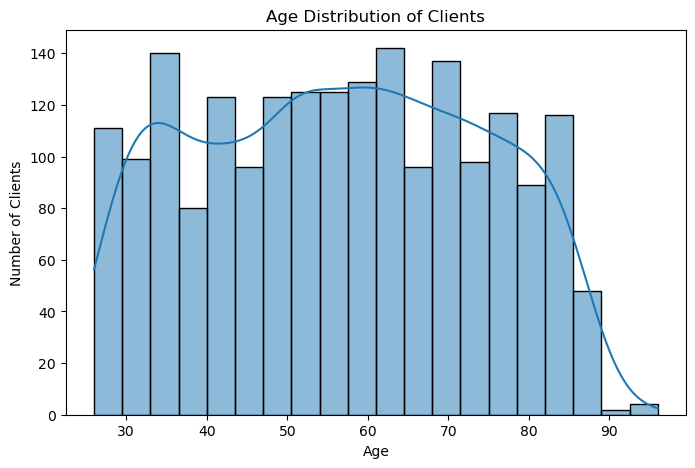

In [587]:
# Visualization 11:Age Distribution of Clients
plt.figure(figsize=(8,5))
sns.histplot(
    data=clients_df,
    x='age',
    bins=20,
    kde=True
)
plt.title('Age Distribution of Clients')
plt.xlabel('Age')
plt.ylabel('Number of Clients')
plt.show()

<Axes: ylabel='age'>

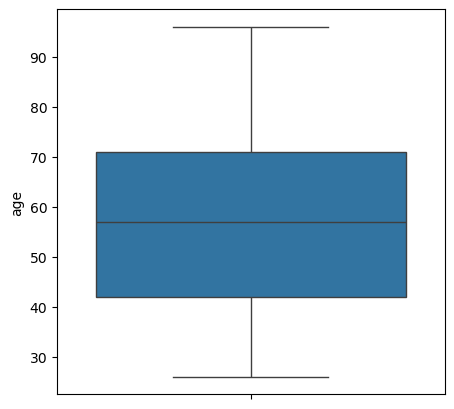

In [588]:
# Box plot
plt.figure(figsize=(5,5))
sns.boxplot(data=clients_df,y='age')

<Axes: ylabel='satisfaction_score'>

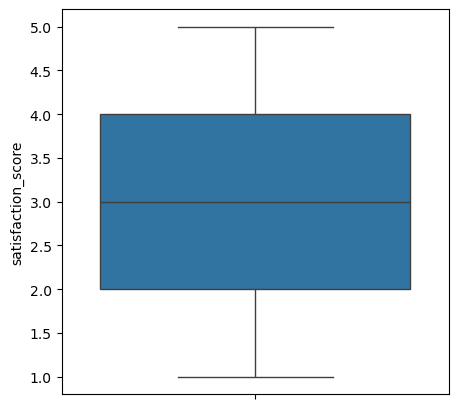

In [589]:
plt.figure(figsize=(5,5))
sns.boxplot(data=clients_df,y='satisfaction_score')

**Property EDA**

In [590]:
prop_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   listing_id        10000 non-null  int64         
 1   tower_number      10000 non-null  int64         
 2   transaction_date  10000 non-null  datetime64[ns]
 3   unit_category     10000 non-null  object        
 4   unit_number       10000 non-null  int64         
 5   floor_area_sqft   10000 non-null  float64       
 6   sale_price        10000 non-null  float64       
 7   listing_status    10000 non-null  object        
 8   client_ref        7305 non-null   object        
dtypes: datetime64[ns](1), float64(2), int64(3), object(3)
memory usage: 703.3+ KB


In [591]:
num_col=[]
for col in prop_df:
  if prop_df[col].dtype in [int,float]:
    num_col.append(col)

In [592]:
num_col

['floor_area_sqft', 'sale_price']

C:\Users\user\AppData\Local\Temp\ipykernel_14900\1763825401.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=prop_df, x='listing_status',palette='coolwarm')


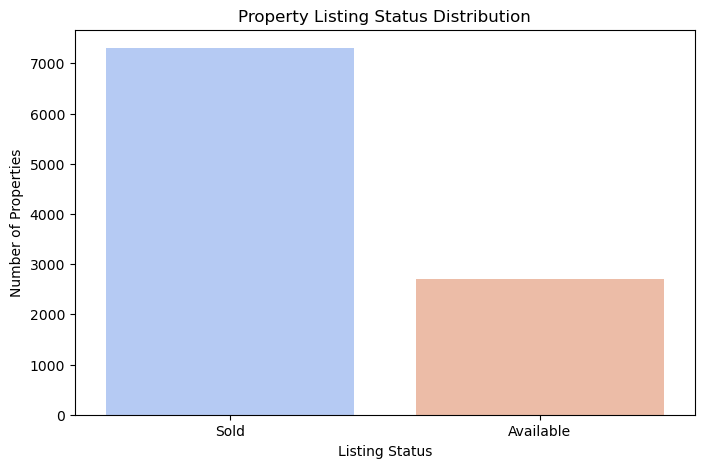

In [593]:
#Listing Status Distribution

plt.figure(figsize=(8,5))

sns.countplot(data=prop_df, x='listing_status',palette='coolwarm')

plt.title('Property Listing Status Distribution')
plt.xlabel('Listing Status')
plt.ylabel('Number of Properties')

plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_14900\1193866004.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=prop_df, x='unit_category',palette='coolwarm')


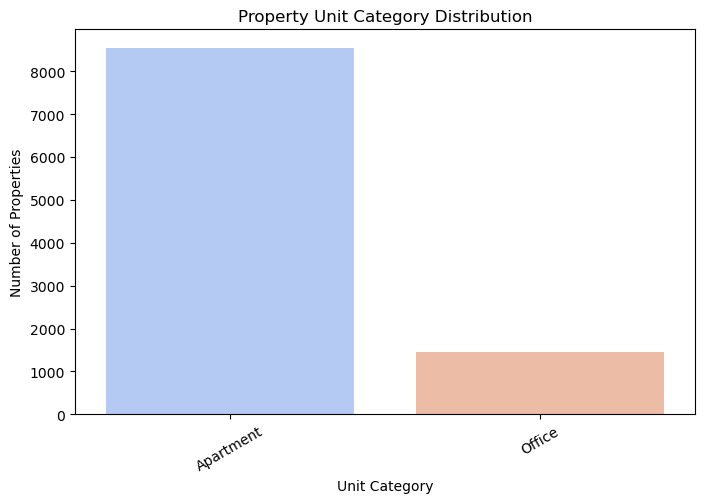

In [594]:
#Property Unit Category Distribution
plt.figure(figsize=(8,5))

sns.countplot(data=prop_df, x='unit_category',palette='coolwarm')

plt.title('Property Unit Category Distribution')
plt.xlabel('Unit Category')
plt.ylabel('Number of Properties')

plt.xticks(rotation=30)

plt.show()

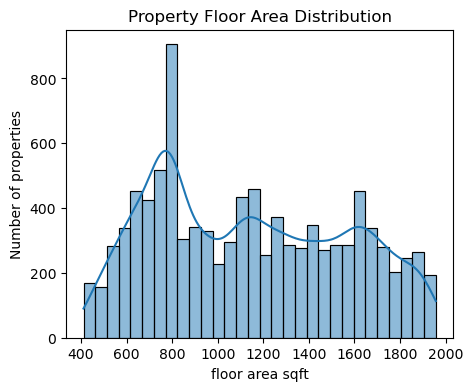

In [595]:
plt.figure(figsize=(5,4))
sns.histplot(data=prop_df,x='floor_area_sqft',bins=30,kde=True)
plt.title('Property Floor Area Distribution')
plt.xlabel('floor area sqft')
plt.ylabel('Number of properties')
plt.show()

Text(0, 0.5, 'sales price')

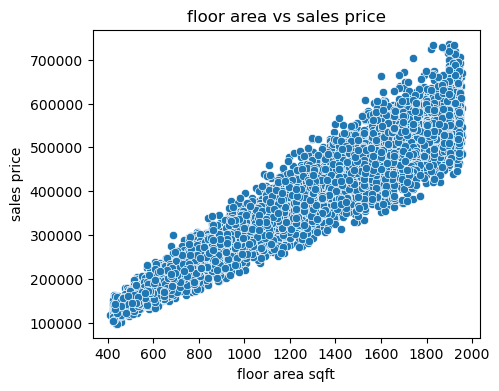

In [596]:
plt.figure(figsize=(5,4))
sns.scatterplot(data=prop_df,x='floor_area_sqft',y='sale_price')
plt.title('floor area vs sales price')
plt.xlabel('floor area sqft')
plt.ylabel('sales price')

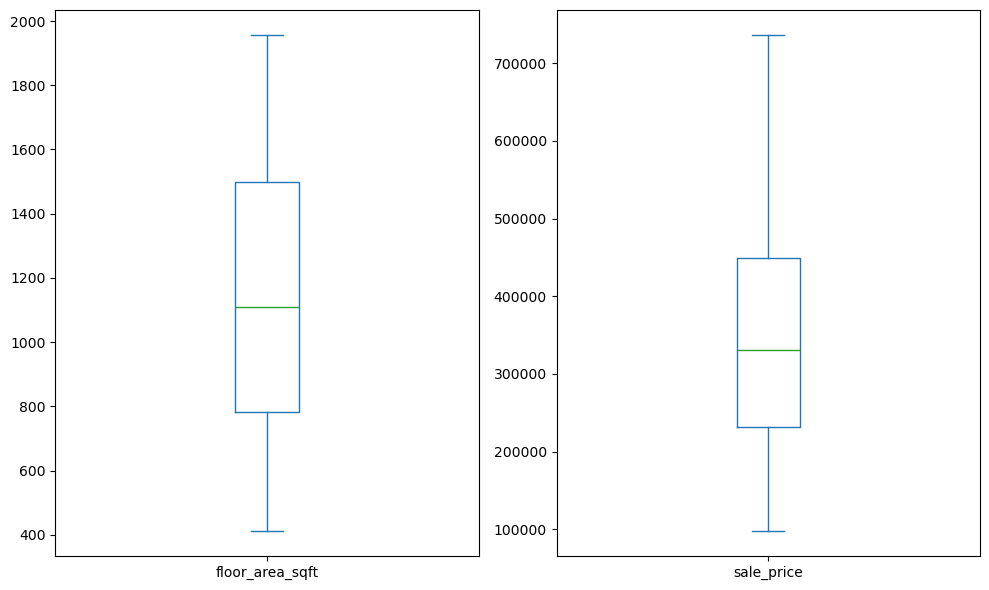

In [597]:
prop_df[num_col].plot(kind='box',subplots=True ,figsize=(10, 6))
plt.tight_layout()
plt.show()

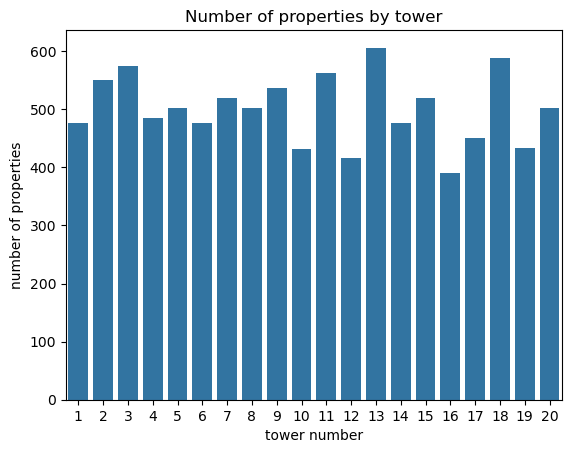

In [598]:
sns.countplot(data=prop_df,x='tower_number')
plt.title('Number of properties by tower')
plt.xlabel('tower number')
plt.ylabel('number of properties')
plt.show()

**BUYER PROPERTY DATASET EDA**

In [599]:
buyer_property_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   listing_id           10000 non-null  int64         
 1   tower_number         10000 non-null  int64         
 2   transaction_date     10000 non-null  datetime64[ns]
 3   unit_category        10000 non-null  object        
 4   unit_number          10000 non-null  int64         
 5   floor_area_sqft      10000 non-null  float64       
 6   sale_price           10000 non-null  float64       
 7   listing_status       10000 non-null  object        
 8   client_ref           7305 non-null   object        
 9   client_id            7305 non-null   object        
 10  client_type          7305 non-null   object        
 11  first_name           7305 non-null   object        
 12  last_name            7305 non-null   object        
 13  date_of_birth        7305 non-nu

<Axes: xlabel='client_type', ylabel='sale_price'>

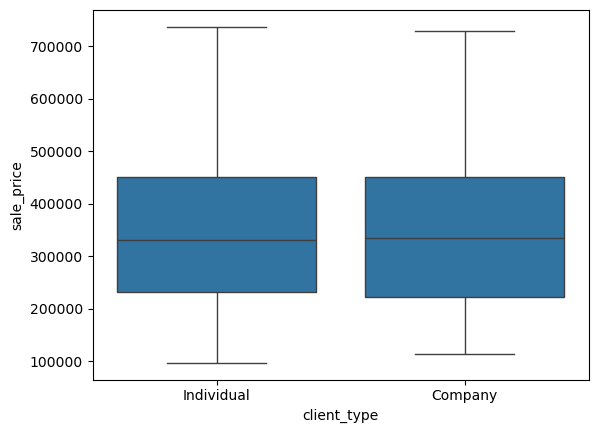

In [600]:
sns.boxplot(data=buyer_property_df,x='client_type',y='sale_price')

C:\Users\user\AppData\Local\Temp\ipykernel_14900\1857689473.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


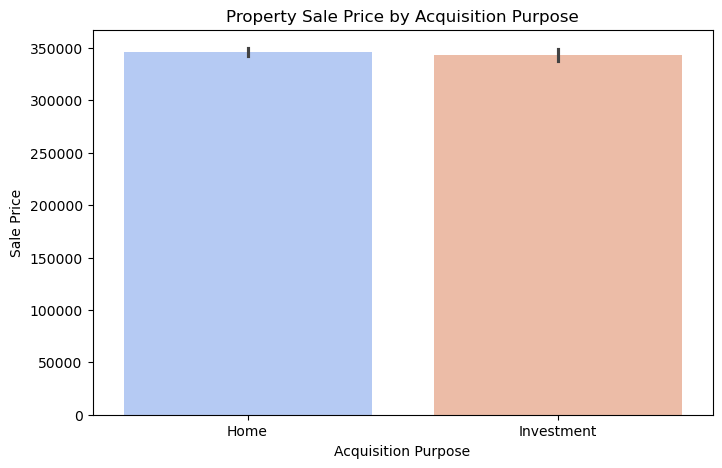

In [601]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=buyer_property_df,
    x='acquisition_purpose',
    y='sale_price',
    palette='coolwarm'
)

plt.title('Property Sale Price by Acquisition Purpose')
plt.xlabel('Acquisition Purpose')
plt.ylabel('Sale Price')

plt.show()

**Client EDA — Insights**

1)Individual clients dominate.

2)Home purchases are more common than investments.

3)Most clients do not use loans.

4)Website is the main referral source.

**Property EDA — Insights**

1)Sold properties dominate.

2)Apartments are the most common category.

3)Property sizes vary considerably.

4)Larger properties generally have higher sale prices.

**Combined EDA — Insights**

1)Individual and company clients have similar sale-price distributions.

2)Home and investment purchases have similar sale-price levels.

3)Property size shows a clearer relationship with sale price than client type.

**Note:**

Encoding is performed only on the Client dataset, as the project focuses on buyer segmentation using client characteristics.

**8 .** **ENCODING**

In [602]:
client_encoded=clients_df.copy()

In [603]:
clients_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   client_id            2000 non-null   object        
 1   client_type          2000 non-null   object        
 2   first_name           2000 non-null   object        
 3   last_name            2000 non-null   object        
 4   date_of_birth        2000 non-null   datetime64[ns]
 5   gender               2000 non-null   object        
 6   country              2000 non-null   object        
 7   region               2000 non-null   object        
 8   acquisition_purpose  2000 non-null   object        
 9   satisfaction_score   2000 non-null   int64         
 10  loan_applied         2000 non-null   object        
 11  referral_channel     2000 non-null   object        
 12  age                  2000 non-null   int32         
dtypes: datetime64[ns](1), int32(1), i

In [604]:
numeric = []
categorical = []

for col in clients_df:
    if col == 'date_of_birth':
        continue
    elif clients_df[col].dtype == object:
        categorical.append(col)
    else:
        numeric.append(col)

print("Numeric Columns:", numeric)
print("Categorical Columns:", categorical)

Numeric Columns: ['satisfaction_score', 'age']
Categorical Columns: ['client_id', 'client_type', 'first_name', 'last_name', 'gender', 'country', 'region', 'acquisition_purpose', 'loan_applied', 'referral_channel']


In [605]:
for col in clients_df:
  print(col, " : ",clients_df[col].nunique())

client_id  :  2000
client_type  :  2
first_name  :  337
last_name  :  224
date_of_birth  :  1889
gender  :  2
country  :  10
region  :  57
acquisition_purpose  :  2
satisfaction_score  :  5
loan_applied  :  2
referral_channel  :  3
age  :  67


In [606]:
cat_cols=['client_type','country','acquisition_purpose','loan_applied']

In [607]:
from sklearn.preprocessing import OneHotEncoder

In [608]:
encode=OneHotEncoder(sparse_output=False)

In [609]:
encoded_data = encode.fit_transform(clients_df[cat_cols])
encoded_data.shape

(2000, 16)

In [610]:
encoded_cols = encode.get_feature_names_out(cat_cols)

In [611]:
encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoded_cols
)
encoded_df.head()

,client_type_Company,client_type_Individual,country_Australia,country_Belgium,country_Canada,country_Denmark,country_France,country_Germany,country_Mexico,country_Russia,country_UK,country_USA,acquisition_purpose_Home,acquisition_purpose_Investment,loan_applied_No,loan_applied_Yes
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0
3,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0


In [612]:
encoded_df.columns

Index(['client_type_Company', 'client_type_Individual', 'country_Australia',
       'country_Belgium', 'country_Canada', 'country_Denmark',
       'country_France', 'country_Germany', 'country_Mexico', 'country_Russia',
       'country_UK', 'country_USA', 'acquisition_purpose_Home',
       'acquisition_purpose_Investment', 'loan_applied_No',
       'loan_applied_Yes'],
      dtype='object')

**9. Feature Scaling**

In [613]:
from sklearn.preprocessing import StandardScaler

In [614]:
scalar=StandardScaler()

In [615]:
numeric

['satisfaction_score', 'age']

In [616]:
data_scaled = scalar.fit_transform(clients_df[numeric])
data_scaled

array([[ 0.68708886,  0.09057818],
       [-1.43573976,  0.43651648],
       [ 0.68708886,  0.66714201],
       ...,
       [ 1.3946984 ,  0.3788601 ],
       [ 0.68708886,  1.47433138],
       [-1.43573976, -1.46614418]])

In [617]:
print(numeric)

['satisfaction_score', 'age']


In [618]:
scaled_df=pd.DataFrame(
    data_scaled,
    columns=numeric
)

In [619]:
x=pd.concat([encoded_df,scaled_df],axis=1)

In [620]:
from sklearn.cluster import KMeans

**10. Elbow Method**

In [621]:
wcss=[]

for k in range(2,11):
  kmeans=KMeans(n_clusters=k,random_state=42,n_init=10)
  kmeans.fit(x)
  wcss.append(kmeans.inertia_)

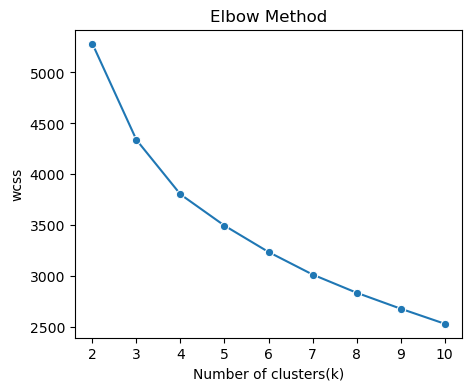

In [622]:
plt.figure(figsize=(5,4))
sns.lineplot(x=range(2,11),y=wcss,marker='o')
plt.xlabel('Number of clusters(k)')
plt.ylabel('wcss')
plt.title('Elbow Method')
plt.show()

**Optimal Clusters:** Based on the Elbow Method, \(k=4\) was selected for client segmentation, balancing cluster compactness and model simplicity.

**11. Clustering Model Selection**

In [623]:
from sklearn.metrics import silhouette_score

In [624]:
kmeans=KMeans(n_clusters=4,random_state=42,n_init=10)
labels=kmeans.fit_predict(x)
score=silhouette_score(x,labels,metric="euclidean")
print(round(score,2))

clients_df['Cluster']=labels

0.19


In [625]:

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

hc = AgglomerativeClustering(n_clusters=4, linkage="ward")
hc_labels = hc.fit_predict(x)

score = silhouette_score(x, hc_labels)
print("Hierarchical Silhouette Score:", round(score, 3))


Hierarchical Silhouette Score: 0.149


### Final Conclusion
K-Means and Hierarchical Clustering were applied for buyer segmentation. K-Means achieved a Silhouette Score of 0.19, compared with 0.14 for Hierarchical Clustering, and was selected for further cluster profiling and investment behavior analysis.

**12. Cluster Interpretation**

In [626]:
clients_df.columns

Index(['client_id', 'client_type', 'first_name', 'last_name', 'date_of_birth',
       'gender', 'country', 'region', 'acquisition_purpose',
       'satisfaction_score', 'loan_applied', 'referral_channel', 'age',
       'Cluster'],
      dtype='object')

In [627]:
clients_df.groupby('Cluster').size()

Cluster
0    599
1    548
2    414
3    439
dtype: int64

In [628]:
clients_df.groupby('Cluster')['age'].mean().round(2)

Cluster
0    71.85
1    40.84
2    69.76
3    42.28
Name: age, dtype: float64

**Note:**

Clusters 1 and 2 contain older buyers on average, while Clusters 0 and 3 contain younger buyers on average.

In [629]:
# Purchase purpose
pd.crosstab(clients_df['Cluster'],
            clients_df['acquisition_purpose'],
            normalize='index').mul(100).round(1)

acquisition_purpose,Home,Investment
Cluster,,
0,72.6,27.4
1,67.3,32.7
2,71.7,28.3
3,64.7,35.3


In [630]:
pd.crosstab(
    clients_df['Cluster'],
    clients_df['loan_applied'],
    normalize='index'
).mul(100).round(1)

loan_applied,No,Yes
Cluster,,
0,66.3,33.7
1,62.6,37.4
2,65.0,35.0
3,58.1,41.9


In [631]:
pd.crosstab(
    clients_df['Cluster'],
    clients_df['client_type'],
    normalize='index'
).mul(100).round(1)

client_type,Company,Individual
Cluster,,
0,1.8,98.2
1,7.5,92.5
2,3.6,96.4
3,8.2,91.8


In [632]:
pd.crosstab(
    clients_df['Cluster'],
    clients_df['country'],
    normalize='index'
).mul(100).round(1)

country,Australia,Belgium,Canada,Denmark,France,Germany,Mexico,Russia,UK,USA
Cluster,,,,,,,,,,
0,1.3,2.3,4.2,0.5,2.0,2.2,2.2,1.8,5.2,78.3
1,2.0,2.7,3.8,1.5,2.0,2.7,1.8,2.2,5.1,76.1
2,2.4,1.7,3.9,0.7,2.9,3.1,1.7,1.9,4.1,77.5
3,2.3,1.6,5.2,0.2,4.1,3.4,2.3,1.1,4.3,75.4


**Note:**
- Identified 4 customer clusters based on age, purchase purpose, investment, loan usage, and satisfaction.
- Clusters 0 & 2: Older, mainly home-use buyers.
- Clusters 1 & 3: Younger buyers with stronger investment tendencies.
- Combining additional features to understand customer segments better and identify meaningful differences between clusters.

In [633]:

buyer_clusters = clients_df[['client_id', 'Cluster']]

# Connecting property records to the buyer's cluster
property_cluster_df = buyer_property_df.merge(
    buyer_clusters,
    left_on='client_ref',
    right_on='client_id',
    how='inner'
)

print("Matched property records:", len(property_cluster_df))
print(property_cluster_df[
    ['client_ref', 'Cluster', 'sale_price', 'floor_area_sqft']
].head())

Matched property records: 7305
  client_ref  Cluster  sale_price  floor_area_sqft
0      C0027        3   300385.62          1160.36
1      C0097        0   208930.81           782.25
2      C0113        0   218585.92           756.21
3      C0141        3   246172.68           743.09
4      C0146        2   212265.67           701.66


In [634]:
cluster_property_summary = property_cluster_df.groupby('Cluster').agg(
    avg_sale_price=('sale_price', 'mean'),
    median_sale_price=('sale_price', 'median'),
    avg_property_size=('floor_area_sqft', 'mean'),
    property_records=('listing_id', 'count')
).round(2)

print(cluster_property_summary)

         avg_sale_price  median_sale_price  avg_property_size  \
Cluster                                                         
0             343385.01          330769.68            1138.54   
1             346611.89          332700.31            1144.63   
2             347155.46          333101.77            1147.49   
3             343589.65          326716.56            1134.56   

         property_records  
Cluster                    
0                    2246  
1                    1957  
2                    1507  
3                    1595  


Cluster 2: Highest average sale price and largest average property size.



Cluster 1: Second-highest average sale price and property size.



Cluster 0: Contains the most property records.



Cluster 3: Has the smallest average property size.

In [635]:
buyer_summary = clients_df.groupby('Cluster').agg(
    avg_age=('age', 'mean'),
    avg_satisfaction=('satisfaction_score', 'mean'),
    investment_buyers=('acquisition_purpose',
        lambda x: (x == 'Investment').mean() * 100),
    corporate_buyers=('client_type',
        lambda x: (x == 'Company').mean() * 100),
    loan_users=('loan_applied',
        lambda x: (x == 'Yes').mean() * 100)
).round(2)

print(buyer_summary)

         avg_age  avg_satisfaction  investment_buyers  corporate_buyers  \
Cluster                                                                   
0          71.85              3.93              27.38              1.84   
1          40.84              2.01              32.66              7.48   
2          69.76              1.49              28.26              3.62   
3          42.28              4.52              35.31              8.20   

         loan_users  
Cluster              
0             33.72  
1             37.41  
2             35.02  
3             41.91  


In [636]:
print(clients_df['client_type'].value_counts())

client_type
Individual    1897
Company        103
Name: count, dtype: int64


In [637]:
print((clients_df.groupby('Cluster')['client_type']
       .apply(lambda x: (x == 'Company').mean() * 100)).round(2))

Cluster
0    1.84
1    7.48
2    3.62
3    8.20
Name: client_type, dtype: float64


In [638]:
company_ids = clients_df.loc[
    clients_df['client_type'] == 'Company', 'client_id'
]

company_properties = buyer_property_df[
    buyer_property_df['client_ref'].isin(company_ids)
]

print("Company property records:", len(company_properties))
print("Unique companies:", company_properties['client_ref'].nunique())
print("Unique properties:", company_properties['listing_id'].nunique())

Company property records: 381
Unique companies: 103
Unique properties: 381


In [639]:
company_purchase_counts = company_properties.groupby('client_ref')['listing_id'].nunique()

print("Companies with multiple properties:",
      (company_purchase_counts > 1).sum())

print("Maximum properties linked to one company:",
      company_purchase_counts.max())

Companies with multiple properties: 103
Maximum properties linked to one company: 13


**Cluster Interpretation**

- **Cluster 0:** Older, mostly home-use buyers with higher satisfaction.
- **Cluster 1:** Younger buyers with lower satisfaction.
- **Cluster 2:** Older buyers with the lowest satisfaction.
- **Cluster 3:** Younger buyers with higher satisfaction and the strongest investment tendency.

*Note: Cluster 3 has the highest Company buyer share (8.03%).*

In [640]:
cluster_names = {
    0: "Emerging Investors",
    1: "Low-Satisfaction Buyers",
    2: "Established Buyers",
    3: "Emerging Buyers"
}

clients_df['Cluster_Label'] = clients_df['Cluster'].map(cluster_names)

In [641]:
print(type(kmeans))
print(x.columns.tolist())

<class 'sklearn.cluster._kmeans.KMeans'>
['client_type_Company', 'client_type_Individual', 'country_Australia', 'country_Belgium', 'country_Canada', 'country_Denmark', 'country_France', 'country_Germany', 'country_Mexico', 'country_Russia', 'country_UK', 'country_USA', 'acquisition_purpose_Home', 'acquisition_purpose_Investment', 'loan_applied_No', 'loan_applied_Yes', 'satisfaction_score', 'age']


In [654]:
#Testing

new_buyer_encoded = pd.DataFrame([{
    'client_type_Company': 0,
    'client_type_Individual': 1,
    'country_Australia': 0,
    'country_Belgium': 0,
    'country_Canada': 0,
    'country_Denmark': 0,
    'country_France': 0,
    'country_Germany': 0,
    'country_Mexico': 0,
    'country_Russia': 0,
    'country_UK': 0,
    'country_USA': 1,
    'acquisition_purpose_Home': 1,
    'acquisition_purpose_Investment': 0,
    'loan_applied_No': 0,
    'loan_applied_Yes': 1,
    'satisfaction_score': 1.5,
    'age': 25
}])

new_buyer_encoded

,client_type_Company,client_type_Individual,country_Australia,country_Belgium,country_Canada,country_Denmark,country_France,country_Germany,country_Mexico,country_Russia,country_UK,country_USA,acquisition_purpose_Home,acquisition_purpose_Investment,loan_applied_No,loan_applied_Yes,satisfaction_score,age
0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,1,1.5,25


In [656]:
new_buyer_encoded[numeric] = scalar.transform(
    new_buyer_encoded[numeric]
)

In [657]:
prediction = kmeans.predict(new_buyer_encoded)

print("Predicted cluster:", prediction[0])

Predicted cluster: 1


In [644]:
import joblib

joblib.dump(kmeans, 'kmeans_model.pkl')

['kmeans_model.pkl']

In [645]:
import os

print(os.path.exists('kmeans_model.pkl'))

True


In [646]:
loaded_model = joblib.load('kmeans_model.pkl')

print("Model loaded successfully!")

Model loaded successfully!


In [649]:
new_buyer_encoded[numeric] = scalar.transform(
    new_buyer_encoded[numeric]
)

In [650]:
import joblib

joblib.dump(kmeans, 'kmeans_model.pkl')
joblib.dump(encode, 'encoder.pkl')
joblib.dump(scalar, 'scaler.pkl')

['scaler.pkl']